# MLP 실습 — 당뇨(이진 분류) · 붓꽃(다중 분류 · 회귀)

수업 실습 데이터(`diabetes_binary_5050split…csv` · `iris_dataset.csv`)로 교재의 **분류 · 회귀 3 가지 문제 유형** 을 같은 틀(학습 루프 5단계)로 풀어 본 노트입니다. 필기 [`mlp_titanic_binary.ipynb`](./mlp_titanic_binary.ipynb) 의 코드 구조를 그대로 가져왔습니다.

- 📖 교재 : `딥러닝` 교재8 **p.81~91** (이진 · 다중 분류 모델 · `BCEWithLogitsLoss` · `CrossEntropyLoss` · 회귀 모델 · `MSELoss` · 평가 · MLP 분류 / 회귀 실습)
- 🔗 앞 노트 : [`gradient_descent_backprop.ipynb`](./gradient_descent_backprop.ipynb)
- 📝 고친 부분은 그 자리와 맨 아래 표에. 🎬 애니메이션은 [`images/`](./images/) 폴더.

| 문제 | 데이터 | 출력층 | 손실 함수 | 정답 텐서 |
|---|---|---|---|---|
| 이진 분류 | 당뇨 70,692 명 · 특성 21 | 뉴런 1 (logit) | `BCEWithLogitsLoss` | `float32`, **(N, 1)** |
| 다중 분류 | 붓꽃 150 송이 · 특성 4 | 뉴런 3 (클래스 수) | `CrossEntropyLoss` | `int64(long)`, **(N,)** |
| 회귀 | 붓꽃 꽃잎 너비 예측 · 특성 3 | 뉴런 1 (항등) | `MSELoss` | `float32`, **(N, 1)** |

In [1]:
# 한글 폰트 설정 (Windows: Malgun Gothic / macOS: AppleGothic)
import platform
import matplotlib.pyplot as plt
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('디바이스:', device)

def to_tensor(a, dtype=torch.float32):
    """넘파이 배열 → 텐서 → 디바이스"""
    return torch.tensor(np.asarray(a), dtype=dtype).to(device)

디바이스: cpu


## 1. 이진 분류 — 당뇨 여부 예측 (교재 p.81, 83~85)

BRFSS 2015 설문 데이터를 **당뇨 / 아님을 50 : 50 으로 맞춘** 버전. 혈압 · 콜레스테롤 · BMI · 흡연 · 운동 · 건강 상태 · 나이 · 소득 등 21 개 특성.

### 1-1. 데이터 · 전처리

In [3]:
diabetes = pd.read_csv('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(diabetes.shape, '결측치', diabetes.isna().sum().sum())
print('정답 비율:', diabetes['Diabetes_binary'].value_counts().to_dict())

X_d = diabetes.drop(columns=['Diabetes_binary']).values
y_d = diabetes['Diabetes_binary'].values

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=0, stratify=y_d)
scaler_d = StandardScaler()
Xd_train_s = scaler_d.fit_transform(Xd_train)     # 학습용으로만 fit
Xd_test_s = scaler_d.transform(Xd_test)

Xd_tr_t, Xd_te_t = to_tensor(Xd_train_s), to_tensor(Xd_test_s)
yd_tr_t, yd_te_t = to_tensor(yd_train), to_tensor(yd_test)            # float32 (0.0 / 1.0)
print('학습용', Xd_tr_t.shape, '평가용', Xd_te_t.shape)

(70692, 22) 결측치 0
정답 비율: {0.0: 35346, 1.0: 35346}
학습용 torch.Size([56553, 21]) 평가용 torch.Size([14139, 21])


### 1-2. 모델 · 손실 · 옵티마이저

데이터가 5 만 6 천 명으로 많아서 배치 크기를 **256** 으로 키웠다(32 면 1 에포크에 1,768 번 업데이트 → 느림).

In [4]:
torch.manual_seed(SEED)
diabetes_model = nn.Sequential(
    nn.Linear(21, 64),   # 입력 21 → 은닉층1 뉴런 64
    nn.ReLU(),
    nn.Linear(64, 32),   # 은닉층1 → 은닉층2 뉴런 32
    nn.ReLU(),
    nn.Linear(32, 1),    # 출력 뉴런 1 (logit) — 시그모이드는 손실 함수 안에
).to(device)

criterion_bin = nn.BCEWithLogitsLoss()
optimizer_d = optim.Adam(diabetes_model.parameters(), lr=0.001)
loader_d = DataLoader(TensorDataset(Xd_tr_t, yd_tr_t), batch_size=256, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))
print('1 에포크 미니배치 수:', len(loader_d))

1 에포크 미니배치 수: 221


### 1-3. 학습 (5 단계)

In [5]:
hist_d = []
for epoch in range(20):
    diabetes_model.train()
    for bx, by in loader_d:
        optimizer_d.zero_grad()                                  # ① 기울기 초기화
        loss = criterion_bin(diabetes_model(bx), by.unsqueeze(1))  # ② 순전파 + ③ 손실
        loss.backward()                                          # ④ 역전파
        optimizer_d.step()                                       # ⑤ 갱신
    diabetes_model.eval()
    with torch.no_grad():
        tr = criterion_bin(diabetes_model(Xd_tr_t), yd_tr_t.unsqueeze(1)).item()
        te_logits = diabetes_model(Xd_te_t)
        te = criterion_bin(te_logits, yd_te_t.unsqueeze(1)).item()
        acc = ((te_logits > 0).float().squeeze(1) == yd_te_t).float().mean().item()
    hist_d.append((tr, te, acc))
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'Epoch {epoch + 1:2d}  학습 BCE {tr:.4f}  평가 BCE {te:.4f}  평가 정확도 {acc:.4f}')

Epoch  1  학습 BCE 0.5073  평가 BCE 0.5014  평가 정확도 0.7537


Epoch  5  학습 BCE 0.4990  평가 BCE 0.4989  평가 정확도 0.7547


Epoch 10  학습 BCE 0.4950  평가 BCE 0.4977  평가 정확도 0.7566


Epoch 15  학습 BCE 0.4928  평가 BCE 0.4982  평가 정확도 0.7565


Epoch 20  학습 BCE 0.4911  평가 BCE 0.4988  평가 정확도 0.7565


### 1-4. 평가 · 기준 모델 비교

In [6]:
diabetes_model.eval()
with torch.no_grad():
    probs_d = torch.sigmoid(diabetes_model(Xd_te_t))
    pred_d = (probs_d >= 0.5).int().cpu().numpy().ravel()
print(f'MLP           평가 정확도: {accuracy_score(yd_test, pred_d):.4f}')
print('혼동 행렬 [[아님→아님, 아님→당뇨], [당뇨→아님, 당뇨→당뇨]]\n', confusion_matrix(yd_test, pred_d))

logreg_d = LogisticRegression(max_iter=1000).fit(Xd_train_s, yd_train)
print(f'로지스틱 회귀 평가 정확도: {logreg_d.score(Xd_test_s, yd_test):.4f}')

MLP           평가 정확도: 0.7565
혼동 행렬 [[아님→아님, 아님→당뇨], [당뇨→아님, 당뇨→당뇨]]
 [[4978 2092]
 [1351 5718]]
로지스틱 회귀 평가 정확도: 0.7485


결과 해석
- MLP **0.7565** vs 로지스틱 회귀 **0.7485** — 은닉층을 넣어도 0.8%p 남짓만 올랐다. 설문 특성 대부분이 0/1 이나 등급이라 선형 모델로도 많이 설명되고, 남은 오차는 특성에 없는 정보(혈당 검사 등) 때문으로 보인다.
- 학습 BCE 는 0.507 → 0.491 로 계속 내려가지만 평가 BCE 는 10 에포크 이후 0.498 근처에서 멈췄다 → 더 학습해도 평가 성능은 안 오른다.
- 당뇨 환자 7,069 명 중 1,351 명(19%)을 '아님' 으로 놓쳤다. 검진용이라면 임계값을 0.5 보다 낮춰 놓치는 사람을 줄이는 쪽이 낫다(정밀도 · 재현율 트레이드오프, Day 029).

## 2. 다중 분류 — 붓꽃 품종 (교재 p.82~83, 85)

출력 뉴런 = 클래스 수 **3**. `CrossEntropyLoss` = 소프트맥스 + 교차 엔트로피. 정답은 원-핫이 아니라 **클래스 번호(0, 1, 2)** 를 `long` 으로.

### 2-1. 데이터 · 전처리

In [7]:
iris = pd.read_csv('iris_dataset.csv')
le = LabelEncoder()
y_i = le.fit_transform(iris['label'])                 # 'setosa' → 0, 'versicolor' → 1, 'virginica' → 2
X_i = iris.drop(columns=['label']).values
print('클래스 번호:', dict(zip(le.classes_, range(3))))

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_i, y_i, test_size=0.2, random_state=0, stratify=y_i)
scaler_i = StandardScaler()
Xi_train_s, Xi_test_s = scaler_i.fit_transform(Xi_train), scaler_i.transform(Xi_test)

Xi_tr_t, Xi_te_t = to_tensor(Xi_train_s), to_tensor(Xi_test_s)
yi_tr_t = to_tensor(yi_train, torch.long)            # CrossEntropyLoss 정답: (N,) 정수
print(Xi_tr_t.shape, yi_tr_t.shape, yi_tr_t.dtype)

클래스 번호: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
torch.Size([120, 4]) torch.Size([120]) torch.int64


### 2-2. 모델 · 학습 (데이터가 120 개뿐이라 미니배치 없이 전체로)

In [8]:
torch.manual_seed(SEED)
multi_model = nn.Sequential(
    nn.Linear(4, 16),    # 입력 4 → 은닉층1 뉴런 16
    nn.ReLU(),
    nn.Linear(16, 8),    # 은닉층2 뉴런 8
    nn.ReLU(),
    nn.Linear(8, 3),     # 출력 뉴런 3 (클래스별 점수 logit) — 소프트맥스는 손실 함수 안에
).to(device)
criterion_multi = nn.CrossEntropyLoss()
optimizer_i = optim.Adam(multi_model.parameters(), lr=0.01)

for epoch in range(100):
    multi_model.train()
    optimizer_i.zero_grad()
    loss = criterion_multi(multi_model(Xi_tr_t), yi_tr_t)   # 출력 (120, 3) · 정답 (120,)
    loss.backward()
    optimizer_i.step()
    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch + 1:3d}  CrossEntropy {loss.item():.4f}')

Epoch  20  CrossEntropy 0.4424
Epoch  40  CrossEntropy 0.1577
Epoch  60  CrossEntropy 0.0667
Epoch  80  CrossEntropy 0.0494
Epoch 100  CrossEntropy 0.0448


### 2-3. 평가 — 가장 점수가 높은 클래스(argmax)

In [9]:
multi_model.eval()
with torch.no_grad():
    test_logits = multi_model(Xi_te_t)
    probs_i = torch.softmax(test_logits, dim=1)               # 확률로 보고 싶을 때만
    pred_i = torch.argmax(test_logits, dim=1).cpu().numpy()   # dim=1 : 클래스 축에서 최댓값의 번호

print('처음 3 송이의 클래스별 확률:\n', probs_i[:3].cpu().numpy().round(3), '→ 예측', pred_i[:3], '정답', yi_test[:3])
print(f'MLP 평가 정확도: {accuracy_score(yi_test, pred_i):.4f}  ({(pred_i == yi_test).sum()} / {len(yi_test)})')
print(f'로지스틱 회귀 평가 정확도: {LogisticRegression(max_iter=1000).fit(Xi_train_s, yi_train).score(Xi_test_s, yi_test):.4f}')
print('혼동 행렬\n', confusion_matrix(yi_test, pred_i))

처음 3 송이의 클래스별 확률:
 [[1.    0.    0.   ]
 [0.    0.998 0.002]
 [1.    0.    0.   ]] → 예측 [0 1 0] 정답 [0 1 0]
MLP 평가 정확도: 1.0000  (30 / 30)
로지스틱 회귀 평가 정확도: 0.9667
혼동 행렬
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


결과 해석 — MLP 30 송이 모두 맞힘, 로지스틱 회귀는 1 송이 틀림(0.9667). 평가용이 30 개뿐이라 **1 송이 = 3.3%p** 라서, 이 차이만으로 MLP 가 낫다고 말하긴 어렵다. 처음 3 송이처럼 확률이 0.998 · 1.000 에 몰리는 건 손실 0.045 까지 내려갔다는 뜻.

### 2-4. 정답 형식 실험 — 원-핫이면? (N, 1) 이면?

In [10]:
with torch.no_grad():
    out = multi_model(Xi_tr_t)
    loss_idx = criterion_multi(out, yi_tr_t)                                  # 클래스 번호 (N,) long
    onehot = torch.nn.functional.one_hot(yi_tr_t, num_classes=3).float()      # 원-핫 (N, 3) float
    loss_onehot = criterion_multi(out, onehot)
print(f'클래스 번호 정답 : {loss_idx:.6f}')
print(f'원-핫(float) 정답 : {loss_onehot:.6f}  ← 같은 값 (PyTorch 1.10 부터 확률 분포 정답도 받음)')

try:
    criterion_multi(out, yi_tr_t.unsqueeze(1))                            # (N, 1) 로 잘못 넣음
except RuntimeError as e:
    print('(N, 1) long 정답 → RuntimeError:', str(e).splitlines()[0])

클래스 번호 정답 : 0.044636
원-핫(float) 정답 : 0.044636  ← 같은 값 (PyTorch 1.10 부터 확률 분포 정답도 받음)
(N, 1) long 정답 → RuntimeError: 0D or 1D target tensor expected, multi-target not supported


> **📝 고친 부분** — 교재 p.83 "정답은 **원-핫 인코딩이 아닌** (N,) 정수형 LongTensor **여야 한다**" → 클래스 번호 (N,) long 이 **기본 · 권장** 형식인 건 맞지만, PyTorch 1.10 이후로는 원-핫 같은 **확률 분포(float, (N, C))** 도 받는다(값도 같다). 진짜로 안 되는 건 **(N, 1)** 처럼 모양이 어긋난 경우.

### 2-5. 특성 2 개(꽃잎 길이 · 너비)로 결정 경계 보기

특성이 4 개면 그림으로 볼 수 없어서, 꽃잎 두 특성만으로 같은 구조의 MLP(입력 2)를 학습해 영역을 칠해 본다.

꽃잎 2 특성 MLP — 마지막 학습 손실 0.0823 · 평가 정확도 0.9667


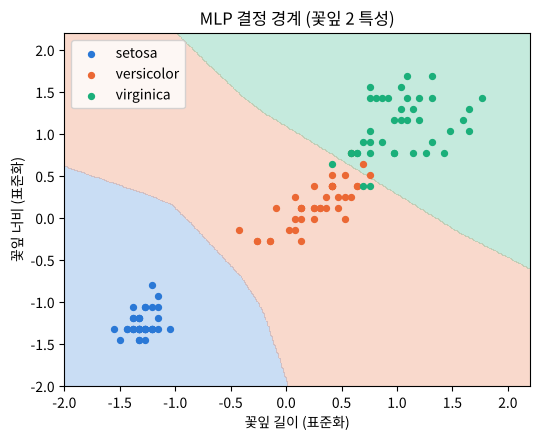

In [11]:
petal_cols = [2, 3]                               # petal length, petal width
Xp_train, Xp_test = Xi_train_s[:, petal_cols], Xi_test_s[:, petal_cols]
Xp_tr_t, Xp_te_t = to_tensor(Xp_train), to_tensor(Xp_test)

torch.manual_seed(SEED)
petal_model = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(), nn.Linear(8, 3)).to(device)
opt_p = optim.Adam(petal_model.parameters(), lr=0.01)
for epoch in range(150):
    petal_model.train()
    opt_p.zero_grad()
    loss = criterion_multi(petal_model(Xp_tr_t), yi_tr_t)
    loss.backward()
    opt_p.step()
petal_model.eval()
with torch.no_grad():
    acc_p = (petal_model(Xp_te_t).argmax(1).cpu().numpy() == yi_test).mean()
print(f'꽃잎 2 특성 MLP — 마지막 학습 손실 {loss.item():.4f} · 평가 정확도 {acc_p:.4f}')

# 결정 경계: 격자의 모든 점을 예측해서 색칠
xx, yy = np.meshgrid(np.linspace(-2, 2.2, 300), np.linspace(-2, 2.2, 300))
with torch.no_grad():
    zz = petal_model(to_tensor(np.c_[xx.ravel(), yy.ravel()])).argmax(1).cpu().numpy().reshape(xx.shape)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#2a78d6', '#eb6834', '#1baf7a'])
for k, c in zip(range(3), ['#2a78d6', '#eb6834', '#1baf7a']):
    ax.scatter(*Xp_train[yi_train == k].T, s=18, color=c, label=le.classes_[k])
ax.set(xlabel='꽃잎 길이 (표준화)', ylabel='꽃잎 너비 (표준화)', title='MLP 결정 경계 (꽃잎 2 특성)')
ax.legend(); plt.tight_layout(); plt.show()

![붓꽃 결정 경계 학습 애니메이션](./images/anim_05_iris_boundary.gif)

ReLU 를 거친 MLP 는 직선 여러 개를 이어 붙인 **꺾인 경계** 를 만든다. setosa 는 처음부터 쉽게 떨어지고, versicolor ↔ virginica 경계가 학습하면서 자리를 잡는다.

## 3. 회귀 — 꽃잎 너비 예측 (교재 p.86~89, 91)

꽃받침 길이 · 너비 · 꽃잎 길이 **3 개** 로 꽃잎 너비(cm)를 예측한다 → 교재 p.86 모델의 `nn.Linear(3, 32)` 와 입력 수가 같다. 출력층은 활성화 함수 없이(항등 함수) 뉴런 1 개.

In [12]:
X_r = iris[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)']].values
y_r = iris['petal width (cm)'].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.2, random_state=0)
scaler_r = StandardScaler()
Xr_train_s, Xr_test_s = scaler_r.fit_transform(Xr_train), scaler_r.transform(Xr_test)

Xr_tr_t, Xr_te_t = to_tensor(Xr_train_s), to_tensor(Xr_test_s)
yr_tr_t = to_tensor(yr_train).unsqueeze(1)          # 정답도 (N, 1) — 출력 모양과 맞춘다
yr_te_t = to_tensor(yr_test).unsqueeze(1)

torch.manual_seed(SEED)
regression_model = nn.Sequential(
    nn.Linear(3, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1),            # 예측할 수치가 1 개 → 출력 뉴런 1 개, 활성화 없음
).to(device)
criterion_reg = nn.MSELoss()
optimizer_r = optim.Adam(regression_model.parameters(), lr=0.01)

for epoch in range(300):
    regression_model.train()
    optimizer_r.zero_grad()                                       # ① 기울기 리셋
    predictions = regression_model(Xr_tr_t)                       # ② 순전파 (수치 예측)
    loss = criterion_reg(predictions, yr_tr_t)                    # ③ MSE
    loss.backward()                                               # ④ 역전파
    optimizer_r.step()                                            # ⑤ 가중치 수정
    if (epoch + 1) % 100 == 0:
        print(f'Epoch {epoch + 1}  학습 MSE {loss.item():.4f}')

Epoch 100  학습 MSE 0.0227
Epoch 200  학습 MSE 0.0182
Epoch 300  학습 MSE 0.0154


In [13]:
regression_model.eval()
with torch.no_grad():
    test_preds = regression_model(Xr_te_t)
    mse = criterion_reg(test_preds, yr_te_t).item()      # 1. MSE
rmse = np.sqrt(mse)                                      # 2. RMSE : 원래 단위(cm)로
print(f'MLP      평가 MSE {mse:.4f} · RMSE {rmse:.4f} cm')
for i in range(3):                                       # 3. 실제값 vs 예측값
    print(f'  실제값: {yr_te_t[i].item():.2f} vs 예측값: {test_preds[i].item():.2f}')

lin = LinearRegression().fit(Xr_train_s, yr_train)
print(f'선형 회귀 평가 RMSE {np.sqrt(mean_squared_error(yr_test, lin.predict(Xr_test_s))):.4f} cm')

MLP      평가 MSE 0.0526 · RMSE 0.2293 cm
  실제값: 2.40 vs 예측값: 1.84
  실제값: 1.00 vs 예측값: 1.23
  실제값: 0.20 vs 예측값: 0.28
선형 회귀 평가 RMSE 0.2284 cm


결과 해석 — MLP RMSE **0.229 cm** ≈ 선형 회귀 **0.228 cm**. 꽃잎 길이와 너비가 거의 직선 관계라 은닉층의 비선형이 할 일이 없다. 오히려 학습 MSE 0.015 vs 평가 MSE 0.053 으로 학습용에 더 맞춰져 있다. **딥러닝이 항상 더 좋은 것은 아니다** — 기준 모델과 꼭 비교하기.

### 3-1. 정답 모양 실수 — (N,) 와 (N, 1)

In [14]:
import warnings
with torch.no_grad(), warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    wrong = criterion_reg(test_preds, yr_te_t.squeeze(1)).item()   # 예측 (30, 1) · 정답 (30,)
print(f'올바른 MSE (30,1) vs (30,1) : {mse:.4f}')
print(f'잘못된 MSE (30,1) vs (30,)  : {wrong:.4f}  ← {wrong / mse:.0f} 배, 에러 없이 경고만')
print('경고:', str(w[0].message)[:90], '…')

올바른 MSE (30,1) vs (30,1) : 0.0526
잘못된 MSE (30,1) vs (30,)  : 0.9875  ← 19 배, 에러 없이 경고만
경고: Using a target size (torch.Size([30])) that is different to the input size (torch.Size([30 …


(30, 1) 과 (30,) 를 빼면 **브로드캐스팅** 으로 (30, 30) 행렬이 되어 "모든 예측 − 모든 정답" 의 평균이 계산된다. 에러가 안 나서 더 위험하다 → 정답은 꼭 `unsqueeze(1)`.

> **📝 고친 부분** — 교재 p.88 · 89 슬라이드 제목이 "**분류**(Classification) 문제" 로 되어 있지만 내용은 **회귀** 학습 루프 · 평가(MSE · RMSE)다. 교재 p.89 `criterion(test_preds, y_test)` 는 `y_test` 가 (N, 1) 텐서일 때만 맞다(위 실험). p.89 `y_test[i].item()` 도 `y_test` 가 pandas Series 면 `.item()` 이 없어서 에러 → 텐서로 바꾼 뒤 사용.

## 📝 고친 부분 정리

| 위치 | 원래 | 고친 내용 |
|---|---|---|
| 교재 p.83 | 다중 분류 정답은 원-핫이 아닌 LongTensor **여야** 한다 | 번호 (N,) long 이 기본, 원-핫 float (N, C) 도 가능. **(N, 1)** 은 에러 |
| 교재 p.85 | `(probs >= 0.5).int().numpy()` | GPU 면 `.cpu()` 필요, (N, 1) → `.ravel()` |
| 교재 p.88 · 89 | 제목 "분류 문제" | **회귀** 문제 |
| 교재 p.89 | `criterion(test_preds, y_test)` | 정답이 (N,) 면 경고만 나고 MSE 가 틀림 → (N, 1) |
| 교재 p.89 | `y_test[i].item()` | Series 가 아니라 **텐서** 일 때 동작 |